✅ Dashboard Final V8 - Layout perfeitamente espaçado e sem encavalamento.


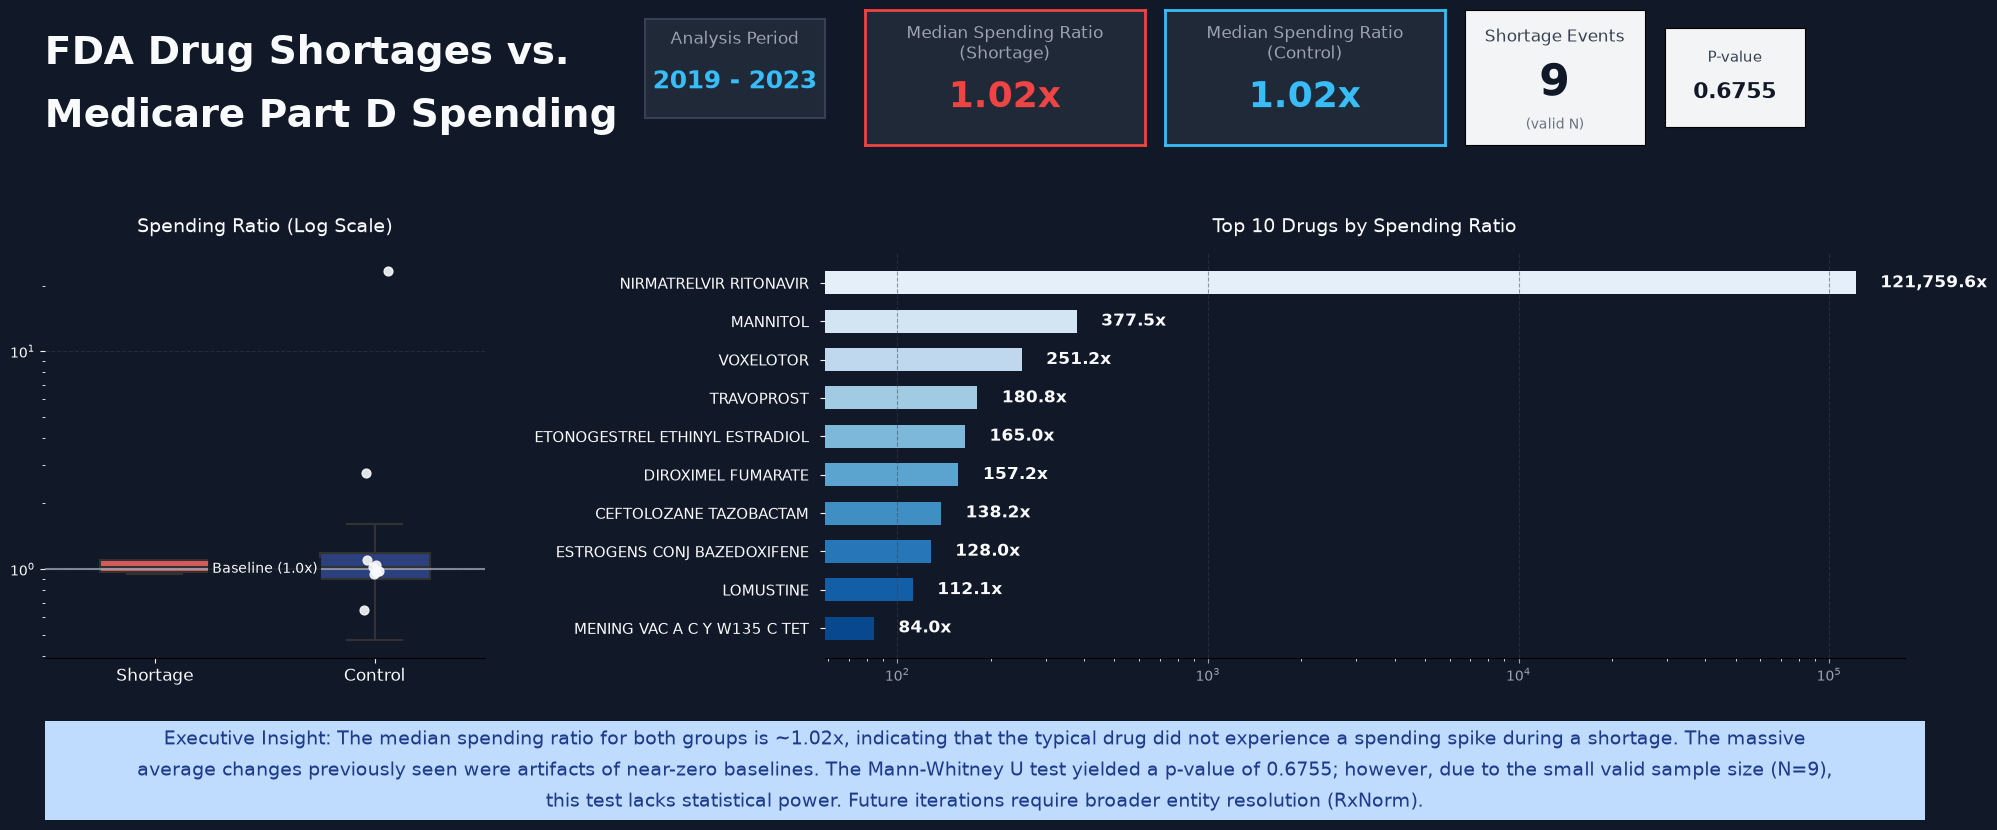

In [8]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import psycopg2
import os
import textwrap
from scipy import stats
import matplotlib.ticker as ticker

# ==========================================
# 1. CONEXÃO COM O BANCO E DADOS REAIS
# ==========================================
db_params = {"dbname": "shortages", "user": "postgres", "password": "r12345", "host": "localhost", "port": "5432"}

query = """
WITH cte_yoy AS (
    SELECT generic_clean, year, total_spending,
           LAG(total_spending) OVER (PARTITION BY generic_clean ORDER BY year) AS prev_spending
    FROM cms_spending_long
)
SELECT y.generic_clean, y.year,
       CAST(y.total_spending AS FLOAT) / NULLIF(y.prev_spending, 0) AS spending_ratio,
       CASE WHEN e.generic_clean IS NOT NULL THEN 'Shortage' ELSE 'Control' END AS group_type
FROM cte_yoy y
LEFT JOIN fda_shortage_events e ON y.generic_clean = e.generic_clean AND y.year = e.event_year
WHERE y.prev_spending > 0;
"""

try:
    conn = psycopg2.connect(**db_params)
    df = pd.read_sql_query(query, conn)
    conn.close()
except Exception as e:
    print(f"Erro ao conectar no banco: {e}")
    raise

shortage_df = df[df['group_type'] == 'Shortage'].dropna(subset=['spending_ratio'])
control_df = df[df['group_type'] == 'Control'].dropna(subset=['spending_ratio'])

median_ratio_shortage = shortage_df['spending_ratio'].median()
median_ratio_control = control_df['spending_ratio'].median()
events_count = len(shortage_df) 
stat, p_value = stats.mannwhitneyu(shortage_df['spending_ratio'], control_df['spending_ratio'], alternative='two-sided')

# ==========================================
# 2. CONFIGURAÇÃO DO DESIGN (DARK MODE)
# ==========================================
BG_COLOR = '#111827'      
CARD_BG = '#1F2937'       
TEXT_WHITE = '#F9FAFB'
TEXT_MUTED = '#9CA3AF'
COLOR_RED = '#EF4444'
COLOR_BLUE = '#38BDF8'
COLOR_WHITE_BG = '#F3F4F6'
COLOR_FOOTER = '#BFDBFE'

plt.rcParams.update({
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": BG_COLOR,
    "text.color": TEXT_WHITE,
    "axes.labelcolor": TEXT_WHITE,
    "xtick.color": TEXT_WHITE,
    "ytick.color": TEXT_WHITE,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Liberation Sans", "sans-serif"]
})

fig = plt.figure(figsize=(20, 9))

# ==========================================
# 3. CABEÇALHO E TÍTULO
# ==========================================
fig.text(0.03, 0.88, "FDA Drug Shortages vs.", fontsize=28, fontweight='bold', color=TEXT_WHITE)
fig.text(0.03, 0.81, "Medicare Part D Spending", fontsize=28, fontweight='bold', color=TEXT_WHITE)

ax_filter = fig.add_axes([0.33, 0.82, 0.09, 0.11]) 
ax_filter.set_facecolor(CARD_BG)
ax_filter.set_xticks([]); ax_filter.set_yticks([])
for spine in ax_filter.spines.values(): 
    spine.set_color('#374151')
    spine.set_linewidth(1.5)
ax_filter.text(0.5, 0.75, "Analysis Period", ha='center', color=TEXT_MUTED, fontsize=12)
ax_filter.text(0.5, 0.3, "2019 - 2023", ha='center', color=COLOR_BLUE, fontsize=18, fontweight='bold')

# ==========================================
# 4. CARTÕES DE KPI (TOP)
# ==========================================
def create_kpi_card(rect, title, value, border_color, text_color, bg_color=CARD_BG):
    ax = fig.add_axes(rect)
    ax.set_facecolor(bg_color)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color(border_color)
        spine.set_linewidth(2)
    ax.text(0.5, 0.75, title, ha='center', va='center', color=TEXT_MUTED if bg_color != COLOR_WHITE_BG else '#4B5563', fontsize=12)
    ax.text(0.5, 0.35, value, ha='center', va='center', color=text_color, fontsize=26, fontweight='bold')

create_kpi_card([0.44, 0.79, 0.14, 0.15], "Median Spending Ratio\n(Shortage)", f"{median_ratio_shortage:.2f}x", COLOR_RED, COLOR_RED)
create_kpi_card([0.59, 0.79, 0.14, 0.15], "Median Spending Ratio\n(Control)", f"{median_ratio_control:.2f}x", COLOR_BLUE, COLOR_BLUE)

# Card Eventos
ax_kpi3 = fig.add_axes([0.74, 0.79, 0.09, 0.15])
ax_kpi3.set_facecolor(COLOR_WHITE_BG)
ax_kpi3.set_xticks([]); ax_kpi3.set_yticks([])
ax_kpi3.text(0.5, 0.8, "Shortage Events", ha='center', va='center', color='#374151', fontsize=12)
ax_kpi3.text(0.5, 0.45, f"{events_count:,}", ha='center', va='center', color='#111827', fontsize=32, fontweight='bold')
ax_kpi3.text(0.5, 0.15, "(valid N)", ha='center', va='center', color='#6B7280', fontsize=10)

# Card P-Value - AUMENTADO PARA NÃO CORTAR O TEXTO
ax_kpi4 = fig.add_axes([0.84, 0.81, 0.07, 0.11])
ax_kpi4.set_facecolor(COLOR_WHITE_BG)
ax_kpi4.set_xticks([]); ax_kpi4.set_yticks([])
ax_kpi4.text(0.5, 0.7, "P-value", ha='center', va='center', color='#374151', fontsize=11)
ax_kpi4.text(0.5, 0.35, f"{p_value:.4f}", ha='center', va='center', color='#111827', fontsize=16, fontweight='bold')

# ==========================================
# 5. GRÁFICO 1 (ESQUERDA - DIMINUÍDO PARA 0.22)
# ==========================================
# Diminuindo a largura para 0.22 para liberar espaço no meio
ax1 = fig.add_axes([0.03, 0.22, 0.22, 0.45]) 
sns.boxplot(data=df, x='group_type', y='spending_ratio', ax=ax1, 
            palette={'Shortage': COLOR_RED, 'Control': '#1E3A8A'}, 
            showfliers=False, width=0.5, linewidth=1.5)

# Plota os pontos APENAS para o Shortage
jitter = np.random.normal(1, 0.04, size=len(shortage_df))
ax1.scatter(jitter, shortage_df['spending_ratio'], color=TEXT_WHITE, alpha=0.9, s=40, zorder=5)

ax1.set_yscale('log')
ax1.set_title('Spending Ratio (Log Scale)', fontsize=14, pad=15, color=TEXT_WHITE)
ax1.set_ylabel('')
ax1.set_xlabel('')
ax1.grid(axis='y', color='#374151', linestyle='--', alpha=0.5)
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False); ax1.spines['left'].set_visible(False)
ax1.set_xlim(-0.5, 1.5)
ax1.tick_params(axis='x', labelsize=12)

ax1.axhline(y=1.0, color=TEXT_MUTED, linestyle='-', linewidth=1.5, alpha=0.8)
ax1.text(0.5, 1.0, 'Baseline (1.0x)', color=TEXT_WHITE, va='center', ha='center', 
         fontsize=10, zorder=10, 
         bbox=dict(facecolor=BG_COLOR, edgecolor='none', alpha=0.9, pad=3))

# ==========================================
# 6. GRÁFICO 2 (DIREITA - COMEÇANDO LONGE E MAIS ESTREITO)
# ==========================================
# Começa em 0.42 (deixando um vão gigante) e largura de 0.54 (para as barras não serem longas)
ax2 = fig.add_axes([0.42, 0.22, 0.54, 0.45]) 
top_10 = df.nlargest(10, 'spending_ratio').sort_values('spending_ratio', ascending=True)

gradient = sns.color_palette("Blues_r", n_colors=len(top_10))
bars = ax2.barh(top_10['generic_clean'], top_10['spending_ratio'], color=gradient, height=0.6)

ax2.set_xscale('log')
ax2.set_title('Top 10 Drugs by Spending Ratio', fontsize=14, pad=15, color=TEXT_WHITE)
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.grid(axis='x', color='#374151', linestyle='--', alpha=0.5)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False); ax2.spines['left'].set_visible(False)

# O segredo para não encavalar: tick_params com pad=10 empurra o texto para a esquerda (perto das barras)
ax2.tick_params(axis='y', colors=TEXT_WHITE, labelsize=11, pad=8)
ax2.tick_params(axis='x', colors=TEXT_MUTED, labelsize=10) 
ax2.xaxis.set_major_formatter(ticker.LogFormatterMathtext())

for bar in bars:
    width = bar.get_width()
    ax2.text(width * 1.2, bar.get_y() + bar.get_height()/2, 
             f'{width:,.1f}x', va='center', fontsize=12, color=TEXT_WHITE, fontweight='bold')

# ==========================================
# 7. RODAPÉ
# ==========================================
ax_footer = fig.add_axes([0.03, 0.04, 0.94, 0.11])
ax_footer.set_facecolor(COLOR_FOOTER)
ax_footer.set_xticks([]); ax_footer.set_yticks([])
for spine in ax_footer.spines.values(): spine.set_visible(False)

texto_insight = (
    "Executive Insight: The median spending ratio for both groups is ~1.02x, indicating that the typical drug did not experience a spending spike during a shortage. "
    "The massive average changes previously seen were artifacts of near-zero baselines. The Mann-Whitney U test yielded a p-value of 0.6755; "
    "however, due to the small valid sample size (N=9), this test lacks statistical power. Future iterations require broader entity resolution (RxNorm)."
)

texto_formatado = textwrap.fill(texto_insight, width=175)

ax_footer.text(0.5, 0.5, texto_formatado, 
               va='center', ha='center', 
               color='#1E3A8A', 
               fontsize=14, 
               fontweight='normal',
               linespacing=1.6)

# ==========================================
# 8. SALVAR E MOSTRAR
# ==========================================
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/executive_dashboard_final.png", dpi=300, bbox_inches="tight", facecolor=BG_COLOR)
print("✅ Dashboard Final V8 - Layout perfeitamente espaçado e sem encavalamento.")
plt.show()